# 01 — Dados: acesso às fontes e verificação

Notebook equivalente a `src/data/` (`fontes.py` + `verificar_fontes.py`). **O desenvolvimento da fase de
dados continua aqui**; os `.py` só são atualizados quando o usuário pedir a modularização (hoje eles
cobrem só as seções 1–7).

O que este notebook faz:
1. Define o acesso às fontes (API do cBioPortal e arquivos públicos), com cache em `data/raw/`.
2. Confere, para cada ômica, cobertura por classe, formato, convenção de cromossomo e armadilhas.
3. Faz um teste de sanidade biológica contra TCGA 2014.
4. Baixa e inspeciona o MAF, a matriz de metilação (seção 8) e a anotação de genes RefGene (seção 9).

Não constrói matriz nenhuma: isso é a Etapa 1, em `02_features`.

**Kernel:** `Python (cg-multiomica)`. Executar de cima para baixo. O que já está em `data/raw/` não é
baixado de novo. A primeira execução baixa ~1,6 GB e leva dezenas de minutos (fetch de mutações pela API +
metilação).

In [1]:
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
RAW = RAIZ / "data" / "raw"

ESTUDO = "stad_tcga_pan_can_atlas_2018"
API = "https://www.cbioportal.org/api"
DATAHUB = f"https://media.githubusercontent.com/media/cBioPortal/datahub/master/public/{ESTUDO}"
XENA = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download"
URLS = {
    "data_cna_hg19.seg": f"{DATAHUB}/data_cna_hg19.seg",
    "probemap_450_hg19.tsv": f"{XENA}/probeMap%2FilluminaMethyl450_hg19_GPL16304_TCGAlegacy",
    "data_methylation_hm450.txt": f"{DATAHUB}/data_methylation_hm450.txt",    # 1,44 GB
    # data_mutations.txt do datahub: objeto LFS inexistente no servidor (404) — MAF vem da API (seção 8)
    "refGene_hg19.txt.gz": "https://hgdownload.soe.ucsc.edu/goldenPath/hg19/database/refGene.txt.gz",  # 8 MB
    # versão corrente do HGNC (muda com o tempo; a baixada é de 2026-10-06): símbolos atuais, anteriores e Entrez
    "hgnc_complete_set.txt": "https://storage.googleapis.com/public-download-files/hgnc/tsv/tsv/hgnc_complete_set.txt",
    # PARTE C (autorizadas pelo usuário em 2026-11-01): pureza ABSOLUTE do PanCanAtlas (página de publicações do GDC) e
    # bandas citogenéticas hg19 (centrômeros) da UCSC
    "TCGA_mastercalls.abs_tables_JSedit.fixed.txt": "https://api.gdc.cancer.gov/data/4f277128-f793-4354-a13d-30cc7fe9f6b5",
    "cytoBand_hg19.txt.gz": "https://hgdownload.soe.ucsc.edu/goldenPath/hg19/database/cytoBand.txt.gz",
}

CROMOSSOMOS = [str(i) for i in range(1, 23)] + ["X", "Y"]
CLASSES = ["STAD_CIN", "STAD_MSI", "STAD_GS", "STAD_EBV", "STAD_POLE"]
CORES = {"STAD_CIN": "#0072B2", "STAD_MSI": "#E69F00", "STAD_GS": "#009E73", "STAD_EBV": "#F0E442"}
LISTAS = {"mutação": "sequenced", "CNV": "log2CNA", "metilação": "methylation_hm450"}
PERFIL_MET = f"{ESTUDO}_methylation_hm450"
LIMIAR_ALTERADO = 0.2  # |log2| acima disso conta como genoma alterado
# Não silenciosas (decisão 2026-10-08) = lista padrão de não sinônimas do maftools. Splice_Region fica fora:
# fica a 1–3 pb do éxon / 3–8 pb do íntron e pode não alterar a proteína.
NAO_SILENCIOSAS = ["Missense_Mutation", "Nonsense_Mutation", "Nonstop_Mutation", "Frame_Shift_Del", "Frame_Shift_Ins",
                   "In_Frame_Del", "In_Frame_Ins", "Splice_Site", "Translation_Start_Site"]

print(f"raiz: {RAIZ} | {date.today()}")

raiz: /mnt/d/Desenvolvimento/imagens_de_cg_para_classificacao | 2026-11-01


## 1. Acesso às fontes

- `api()` — GET na API do cBioPortal (POST, se houver corpo). Com `cache`, guarda o JSON em `data/raw/`.
- `baixar()` — baixa um arquivo de `URLS`. A rede já caiu para poucos KB/s no meio de downloads, então
  ele retoma um `.part` deixado por tentativa anterior e recusa arquivo incompleto.
- `normalizar_cromossomos()` — as fontes usam três convenções (MAF `23`/`24`, `.seg` `23`, probeMap
  `chrX`). Leva tudo para `1`…`22`, `X`, `Y`, e **falha** com valor desconhecido em vez de descartar:
  um cromossomo descartado aqui some do universo comum sem aviso.

In [2]:
def api(caminho: str, corpo: dict | None = None, cache: str | None = None):
    arquivo = RAW / cache if cache else None
    if arquivo and arquivo.exists():
        return json.loads(arquivo.read_text())
    url = f"{API}/{caminho}"
    # timeout longo: o fetch de todas as mutações pode passar de 10 min antes do primeiro byte
    r = requests.post(url, json=corpo, timeout=3600) if corpo is not None else requests.get(url, timeout=3600)
    r.raise_for_status()
    dados = r.json()
    if arquivo:
        RAW.mkdir(parents=True, exist_ok=True)
        arquivo.write_text(json.dumps(dados))
    return dados


def baixar(nome: str, tentativas: int = 5) -> Path:
    destino = RAW / nome
    if destino.exists():
        return destino
    RAW.mkdir(parents=True, exist_ok=True)
    parcial = RAW / f"{nome}.part"
    for tentativa in range(1, tentativas + 1):
        ja = parcial.stat().st_size if parcial.exists() else 0
        try:
            with requests.get(URLS[nome], headers={"Range": f"bytes={ja}-"} if ja else {}, stream=True, timeout=600) as r:
                r.raise_for_status()
                retomou = r.status_code == 206
                total = int(r.headers["Content-Range"].split("/")[-1]) if retomou else int(r.headers.get("Content-Length", 0))
                with open(parcial, "ab" if retomou else "wb") as f:
                    for bloco in r.iter_content(1 << 16):  # blocos pequenos: a queda perde no máximo 64 KB
                        f.write(bloco)
            break
        except (requests.ConnectionError, requests.exceptions.ChunkedEncodingError) as erro:
            print(f"{nome}: conexão caiu em {parcial.stat().st_size:,} bytes ({type(erro).__name__}), "
                  f"retomando — tentativa {tentativa}/{tentativas}")
    else:
        raise IOError(f"{nome}: {tentativas} quedas seguidas. Rode de novo para retomar do .part.")
    if total and parcial.stat().st_size != total:
        raise IOError(f"{nome}: {parcial.stat().st_size} de {total} bytes. Rode de novo para retomar.")
    parcial.rename(destino)
    return destino


def normalizar_cromossomos(serie: pd.Series) -> pd.Series:
    c = serie.astype(str).str.removeprefix("chr").replace({"23": "X", "24": "Y"})
    invalidos = sorted(set(c) - set(CROMOSSOMOS))
    if invalidos:
        raise ValueError(f"cromossomos fora de 1–22/X/Y: {invalidos}")
    return c

In [3]:
# autoteste da normalização
assert normalizar_cromossomos(pd.Series(["chr7", "7", 23, "24", "chrX"])).tolist() == ["7", "7", "X", "Y", "X"]
try:
    normalizar_cromossomos(pd.Series(["chrUn_gl000220"]))
    raise AssertionError("cromossomo inválido deveria falhar")
except ValueError:
    pass
print("normalizar_cromossomos: ok")

normalizar_cromossomos: ok


## 2. Rótulo e cobertura por ômica

Rótulo: atributo de **paciente** `SUBTYPE`. Cobertura: listas de amostras do cBioPortal para cada ômica.
A interseção das três é o n máximo de modelagem.

In [4]:
sub = pd.DataFrame(api(f"studies/{ESTUDO}/clinical-data?clinicalDataType=PATIENT&attributeId=SUBTYPE",
                       cache="subtipos.json"))
rotulo = sub.set_index("patientId")["value"]
amostras = {omica: set(api(f"sample-lists/{ESTUDO}_{lista}/sample-ids", cache=f"amostras_{lista}.json"))
            for omica, lista in LISTAS.items()}
todas = set().union(*amostras.values())
assert all(a.endswith("-01") for a in todas), "há amostra que não é tumor primário (-01)"
assert len({a[:12] for a in todas}) == len(todas), "há paciente com mais de uma amostra"
amostras["3 ômicas"] = set.intersection(*(amostras[o] for o in LISTAS))

print(f"Pacientes com SUBTYPE: {len(rotulo)}")
print("Amostras por lista:", {o: len(ids) for o, ids in amostras.items()})
print("Sem SUBTYPE entre as que têm as 3 ômicas:", sum(1 for a in amostras["3 ômicas"] if a[:12] not in rotulo.index))

cobertura = pd.DataFrame({"rotulados": rotulo.value_counts()})
for nome, ids in amostras.items():
    cobertura[nome] = rotulo.reindex([a[:12] for a in ids]).value_counts()
cobertura = cobertura.reindex(CLASSES).fillna(0).astype(int).rename_axis("classe")
cobertura.loc["total sem POLE"] = cobertura.drop("STAD_POLE").sum()
cobertura["perda"] = cobertura["rotulados"] - cobertura["3 ômicas"]
cobertura["perda %"] = (100 * cobertura["perda"] / cobertura["rotulados"]).round(1)
cobertura

Pacientes com SUBTYPE: 383
Amostras por lista: {'mutação': 436, 'CNV': 438, 'metilação': 393, '3 ômicas': 389}
Sem SUBTYPE entre as que têm as 3 ômicas: 46


,rotulados,mutação,CNV,metilação,3 ômicas,perda,perda %
classe,,,,,,,
STAD_CIN,223,223,223,202,202,21,9.4
STAD_MSI,73,73,73,59,59,14,19.2
STAD_GS,50,50,50,46,46,4,8.0
STAD_EBV,30,30,30,29,29,1,3.3
STAD_POLE,7,7,7,7,7,0,0.0
total sem POLE,376,376,376,336,336,40,10.6


In [5]:
# sexo: usado no 02_features para medir o efeito da inativação do X na metilação (decisão 5)
sexo = pd.DataFrame(api(f"studies/{ESTUDO}/clinical-data?clinicalDataType=PATIENT&attributeId=SEX",
                        cache="sexo.json")).set_index("patientId")["value"]
print("SEX:", sexo.value_counts(dropna=False).to_dict(), f"· pacientes rotulados sem SEX: {rotulo.index.difference(sexo.index).size}")
pd.crosstab(rotulo.rename("subtipo"), sexo.reindex(rotulo.index).rename("sexo"), normalize="index").round(2)

SEX: {'Male': 284, 'Female': 156} · pacientes rotulados sem SEX: 0


sexo,Female,Male
subtipo,,
STAD_CIN,0.31,0.69
STAD_EBV,0.13,0.87
STAD_GS,0.34,0.66
STAD_MSI,0.52,0.48
STAD_POLE,0.29,0.71


A metilação é o gargalo (393 amostras), e o **MSI é a classe que mais perde** (19%).

## 3. CNV — segmentos (`data_cna_hg19.seg`, datahub do cBioPortal, hg19)

`seg.mean` = log2(tumor/normal). Gene fora de qualquer segmento recebe `NaN`, não 0.

In [6]:
seg = pd.read_csv(baixar("data_cna_hg19.seg"), sep="\t")
print("colunas:", list(seg.columns))
seg.columns = ["amostra", "chrom", "inicio", "fim", "n_sondas", "log2"]
assert set(seg.amostra) == amostras["CNV"], "amostras do .seg diferem da lista log2CNA da API"
print("cromossomos como vêm:", sorted(seg.chrom.astype(str).unique(), key=lambda c: (len(c), c)))
seg["chrom"] = normalizar_cromossomos(seg.chrom)

por_amostra = seg.groupby("amostra").size()
print(f"{seg.amostra.nunique()} amostras · {len(seg):,} segmentos · mediana {por_amostra.median():.0f} por amostra "
      f"({por_amostra.min()}–{por_amostra.max()})")
print(f"log2 de {seg.log2.min():.2f} a {seg.log2.max():.2f} · NaN: {seg.log2.isna().sum()}")
inicio_chr1 = seg[seg.chrom == "1"].groupby("amostra").inicio.min()
print(f"1º segmento do chr1 começa, na mediana, em {inicio_chr1.median() / 1e6:.1f} Mb")

colunas: ['ID', 'chrom', 'loc.start', 'loc.end', 'num.mark', 'seg.mean']
cromossomos como vêm: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23']


438 amostras · 89,769 segmentos · mediana 156 por amostra (33–1559)
log2 de -7.58 a 4.54 · NaN: 0
1º segmento do chr1 começa, na mediana, em 3.2 Mb


**Fração do genoma alterado** (|log2| > 0,2, ponderada pelo comprimento do segmento). É a medida de
aneuploidia que o TCGA usou para separar GS de CIN.

In [7]:
seg["comp"] = seg.fim - seg.inicio
seg["comp_alterado"] = seg.comp * (seg.log2.abs() > LIMIAR_ALTERADO)
soma = seg.groupby("amostra")[["comp", "comp_alterado"]].sum()
fga = soma.comp_alterado / soma.comp
fga.groupby(rotulo.reindex(fga.index.str[:12]).values).describe()[["count", "25%", "50%", "75%"]].round(3)

,count,25%,50%,75%
STAD_CIN,223.0,0.172,0.326,0.473
STAD_EBV,30.0,0.030,0.119,0.203
STAD_GS,50.0,0.000,0.003,0.024
STAD_MSI,73.0,0.050,0.075,0.126
STAD_POLE,7.0,0.147,0.207,0.427


## 4. Metilação — HM450 por sonda

Metadados das 396 mil sondas pela API. A coluna `DESCRIPTION` deveria trazer a região (TSS1500, TSS200,
1stExon…), que é o que definiria o promotor.

In [8]:
meta = pd.DataFrame([{"sonda": x["stableId"], **x.get("genericEntityMetaProperties", {})}
                     for x in api(f"generic-assay-meta/{PERFIL_MET}?projection=SUMMARY", cache="sondas_hm450_meta.json")])
meta["NAME"] = meta.NAME.fillna("NA")
genes_sonda = meta.NAME.str.split(";")
tem = lambda gene: genes_sonda.apply(lambda g: gene in g)  # noqa: E731
sem_regiao = meta.DESCRIPTION.isna()

print(f"{len(meta):,} sondas · sem gene: {(meta.NAME == 'NA').sum():,}")
print(f"DESCRIPTION ausente: {sem_regiao.sum():,} ({sem_regiao.mean():.1%}) · "
      f"com ID de transcrito no lugar da região: {meta.DESCRIPTION.str.contains(r'N[MR]_', na=False).sum():,}")
print(f"sondas do MLH1: {tem('MLH1').sum()}, sem região: {(tem('MLH1') & sem_regiao).sum()}")

396,065 sondas · sem gene: 57,685
DESCRIPTION ausente: 320,793 (81.0%) · com ID de transcrito no lugar da região: 11,035


sondas do MLH1: 47, sem região: 39


A região falta em 81% das sondas, inclusive nas do MLH1, então **não serve para definir promotor**. O
promotor vai ser definido por coordenada (sonda × TSS do gene). As coordenadas hg19 das sondas vêm do
probeMap do Xena.

In [9]:
mapa = pd.read_csv(baixar("probemap_450_hg19.tsv"), sep="\t").rename(columns={"#id": "sonda"})
sem_chrom = mapa.chrom.isna()  # têm posição mas não cromossomo: posição inútil
print("colunas:", list(mapa.columns), f"· sem cromossomo (descartadas): {sem_chrom.sum()}")
mapa = mapa[~sem_chrom]
print("cromossomos como vêm:", sorted(mapa.chrom.unique(), key=lambda c: (len(c), c)))
mapa["chrom"] = normalizar_cromossomos(mapa.chrom)

cobertas = meta.sonda.isin(mapa.sonda)
print(f"cobre {cobertas.sum():,} de {len(meta):,} sondas (faltam {(~cobertas).sum()}) · "
      f"em X/Y: {mapa[mapa.sonda.isin(meta.sonda)].chrom.isin(['X', 'Y']).sum():,}")
mapa.head()

colunas: ['sonda', 'gene', 'chrom', 'chromStart', 'chromEnd', 'strand'] · sem cromossomo (descartadas): 35
cromossomos como vêm: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX', 'chrY', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22']


cobre 395,950 de 396,065 sondas (faltam 115) · em X/Y: 10,141


,sonda,gene,chrom,chromStart,chromEnd,strand
0,cg13332474,.,7,25935146,25935148,.
1,cg00651829,"RSPH14,GNAZ",22,23413065,23413067,.
2,cg17027195,AUTS2,7,69064092,69064094,.
3,cg22461835,ADRA1A,8,26723364,26723366,.
4,cg03050183,AP5B1,11,65547777,65547779,.


### Sanidade biológica (TCGA 2014)

Beta de todas as sondas de MLH1 e CDKN2A, buscadas pela API. Esperado: promotor de MLH1 hipermetilado
no MSI e CDKN2A hipermetilado no EBV. A tabela mostra as 5 sondas que mais separam a classe-alvo das
outras (mediana da classe − maior mediana entre as outras).

In [10]:
beta = pd.DataFrame(api(f"generic_assay_data/{PERFIL_MET}/fetch",
                        {"genericAssayStableIds": meta.sonda[tem("MLH1") | tem("CDKN2A")].tolist(),
                         "sampleListId": PERFIL_MET},
                        cache="beta_mlh1_cdkn2a.json"))
beta["value"] = pd.to_numeric(beta.value)
beta["classe"] = beta.patientId.map(rotulo)
print(f"{len(beta):,} valores · beta de {beta.value.min():.3f} a {beta.value.max():.3f}")

mediana = beta.dropna(subset=["classe"]).pivot_table(index="genericAssayStableId", columns="classe",
                                                     values="value", aggfunc="median")
separacao = {}
for gene, classe in [("MLH1", "STAD_MSI"), ("CDKN2A", "STAD_EBV")]:
    outras = [c for c in CLASSES[:4] if c != classe]
    t = mediana[mediana.index.isin(meta.sonda[tem(gene)])][CLASSES[:4]]
    separacao[gene] = t.assign(diferenca=t[classe] - t[outras].max(axis=1)).sort_values("diferenca", ascending=False)
separacao["MLH1"].head().round(2)

21,985 valores · beta de 0.007 a 0.969


classe,STAD_CIN,STAD_MSI,STAD_GS,STAD_EBV,diferenca
genericAssayStableId,,,,,
cg13846866,0.05,0.67,0.05,0.05,0.61
cg03497419,0.03,0.62,0.03,0.03,0.59
cg17641046,0.04,0.63,0.04,0.04,0.59
cg06108510,0.03,0.57,0.03,0.02,0.55
cg23658326,0.02,0.55,0.02,0.02,0.53


In [11]:
separacao["CDKN2A"].head().round(2)

classe,STAD_CIN,STAD_MSI,STAD_GS,STAD_EBV,diferenca
genericAssayStableId,,,,,
cg14430974,0.03,0.03,0.03,0.52,0.50
cg10848754,0.03,0.03,0.03,0.43,0.40
cg07562918,0.22,0.29,0.18,0.58,0.29
cg13601799,0.03,0.29,0.03,0.56,0.27
cg00718440,0.06,0.07,0.06,0.32,0.25


## 5. O rótulo já está nos canais

O TCGA atribuiu os subtipos por árvore de decisão: EBV → MSI → GS/CIN pelo grau de aneuploidia. Os três
painéis mostram, por amostra, as variáveis dessa árvore.

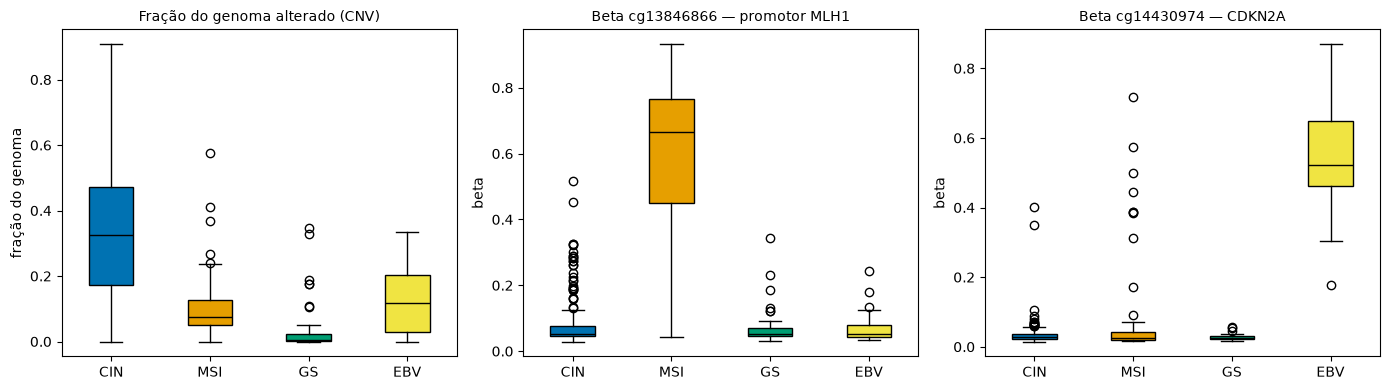

In [12]:
top_mlh1, top_cdkn2a = separacao["MLH1"].index[0], separacao["CDKN2A"].index[0]
por_sonda = lambda sonda: beta[beta.genericAssayStableId == sonda].set_index("sampleId").value  # noqa: E731
paineis = [(fga, "Fração do genoma alterado (CNV)", "fração do genoma"),
           (por_sonda(top_mlh1), f"Beta {top_mlh1} — promotor MLH1", "beta"),
           (por_sonda(top_cdkn2a), f"Beta {top_cdkn2a} — CDKN2A", "beta")]

fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for ax, (serie, titulo, eixo_y) in zip(eixos, paineis):
    classe = rotulo.reindex(serie.index.str[:12]).values
    caixas = ax.boxplot([serie[classe == c] for c in CLASSES[:4]], patch_artist=True, medianprops={"color": "black"},
                        tick_labels=[c.removeprefix("STAD_") for c in CLASSES[:4]])
    for caixa, c in zip(caixas["boxes"], CLASSES[:4]):
        caixa.set_facecolor(CORES[c])
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel(eixo_y)
fig.tight_layout()

## 6. Símbolos de gene entre fontes

Lista de genes mutados pela API (já com Entrez ID), comparada por símbolo com os genes das sondas.

In [13]:
mut = pd.DataFrame(api("mutated-genes/fetch", {"studyIds": [ESTUDO]}, cache="genes_mutados.json"))
g_mut = set(mut.hugoGeneSymbol)
g_mapa = set(mapa.gene[mapa.gene != "."].str.split(",").explode())
g_meta = set(meta.NAME[meta.NAME != "NA"].str.split(";").explode())
print(f"genes mutados: {len(g_mut):,} · com sonda: probeMap {len(g_mapa):,}, NAME do cBioPortal {len(g_meta):,}")
print(f"mutados achados por símbolo no probeMap: {len(g_mut & g_mapa):,} ({len(g_mut & g_mapa) / len(g_mut):.1%}) · "
      f"no NAME: {len(g_mut & g_meta):,} ({len(g_mut & g_meta) / len(g_mut):.1%})")
print("exemplos ausentes do probeMap:", sorted(g_mut - g_mapa)[:12])

genes mutados: 17,436 · com sonda: probeMap 34,010, NAME do cBioPortal 34,779
mutados achados por símbolo no probeMap: 16,023 (91.9%) · no NAME: 16,497 (94.6%)
exemplos ausentes do probeMap: ['AARS1', 'ABHD18', 'ABITRAM', 'ABRAXAS1', 'ABRAXAS2', 'ABTB3', 'ACBD6', 'ACKR5', 'ACP3', 'ACP4', 'ACP7', 'ACSM2B']


O MAF usa símbolos HGNC atuais (`AARS1`, `ADGRA1`) e o probeMap usa os antigos. **Casar por símbolo
cru perde ~8% dos genes em silêncio**: a chave de gene precisa ser estável (Entrez ID ou tabela de
símbolos anteriores do HGNC).

## 7. Coordenadas de gene no cBioPortal

In [14]:
ref = pd.DataFrame(api("reference-genome-genes/hg19", cache="genes_hg19_cbioportal.json"))
print(f"{len(ref):,} genes, {((ref.start == 0) & (ref.end == 0)).sum():,} com início e fim = 0")
ref.head(3)

44,824 genes, 44,824 com início e fim = 0


,referenceGenomeId,entrezGeneId,hugoGeneSymbol,chromosome,cytoband,start,end
0,1,1,A1BG,19,19q13.43,0,0
1,1,2,A2M,12,12p13.31,0,0
2,1,9,NAT1,8,8p22,0,0


Todas zeradas: **a coordenada de gene (TSS para o promotor, posição para a ordenação) precisa vir de
anotação hg19 externa** (GENCODE v19 ou UCSC RefGene, decisão pendente).

## 8. MAF e matriz de metilação

- **Metilação:** `data_methylation_hm450.txt` do datahub do cBioPortal (decisão do usuário, 2026-10-08).
- **MAF:** o `data_mutations.txt` do datahub está quebrado. O ponteiro LFS existe, mas a API de LFS do
  GitHub responde *"Object does not exist on the server"* (verificado em 2026-10-08). O MAF vem então
  da **API do cBioPortal**, que é o mesmo estudo, a mesma versão e a mesma fonte do rótulo. O fetch
  completo leva dezenas de minutos e é guardado como veio, em `data/raw/mutacoes_api.json`.

In [15]:
print(f"metilação: {baixar('data_methylation_hm450.txt').stat().st_size / 1e6:,.1f} MB")

mutacoes_api = api(f"molecular-profiles/{ESTUDO}_mutations/mutations/fetch?projection=DETAILED&pageSize=500000&pageNumber=0",
                   {"sampleListId": f"{ESTUDO}_sequenced"}, cache="mutacoes_api.json")
print(f"mutações: {len(mutacoes_api):,} registros · {(RAW / 'mutacoes_api.json').stat().st_size / 1e6:,.1f} MB")


def linhas_de_comentario(caminho: Path) -> int:
    """Quantas linhas '#' abrem o arquivo, para pular na leitura."""
    with open(caminho) as f:
        return next(i for i, linha in enumerate(f) if not linha.startswith("#"))

metilação: 1,442.9 MB


mutações: 147,953 registros · 136.0 MB


### MAF

A tabela mostra todas as classes de variante que vieram e quais entram na contagem por gene
(`NAO_SILENCIOSAS`, decisão de 2026-10-08).

In [16]:
# Campos da API → nomes do formato MAF. A API devolve 'chr', não 'chromosome' (armadilha do projeto irmão).
CAMPOS_MAF = {"gene.hugoGeneSymbol": "Hugo_Symbol", "entrezGeneId": "Entrez_Gene_Id", "ncbiBuild": "NCBI_Build",
              "chr": "Chromosome", "startPosition": "Start_Position", "endPosition": "End_Position",
              "mutationType": "Variant_Classification", "variantType": "Variant_Type", "sampleId": "Tumor_Sample_Barcode"}
maf = pd.json_normalize(mutacoes_api)
faltando = set(CAMPOS_MAF) - set(maf.columns)
assert not faltando, f"campos ausentes na resposta da API: {faltando}"
maf = maf[list(CAMPOS_MAF)].rename(columns=CAMPOS_MAF)

amostras_maf = set(maf.Tumor_Sample_Barcode)
print(f"{len(maf):,} variantes · {len(amostras_maf)} amostras · {maf.Hugo_Symbol.nunique():,} genes")
print(f"amostras da lista 'sequenced' sem nenhuma variante: {sorted(amostras['mutação'] - amostras_maf)} · "
      f"fora da lista: {len(amostras_maf - amostras['mutação'])}")
print("NCBI_Build:", maf.NCBI_Build.value_counts().to_dict())
print("cromossomos como vêm:", sorted(maf.Chromosome.astype(str).unique(), key=lambda c: (len(c), c)))
print("Entrez_Gene_Id ausente ou ≤ 0:", int((maf.Entrez_Gene_Id.fillna(0) <= 0).sum()))

classes_maf = maf.Variant_Classification.value_counts().rename("variantes").to_frame()
classes_maf["entra na contagem"] = classes_maf.index.isin(NAO_SILENCIOSAS)
classes_maf

147,953 variantes · 435 amostras · 17,436 genes
amostras da lista 'sequenced' sem nenhuma variante: ['TCGA-FP-8209-01'] · fora da lista: 0
NCBI_Build: {'GRCh37': 147935, 'GRCh38': 18}
cromossomos como vêm: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24']
Entrez_Gene_Id ausente ou ≤ 0: 0


,variantes,entra na contagem
Variant_Classification,,
Missense_Mutation,114707,True
Frame_Shift_Del,16710,True
Nonsense_Mutation,6152,True
Frame_Shift_Ins,3982,True
Splice_Site,2702,True
Splice_Region,1840,False
In_Frame_Del,1493,True
Nonstop_Mutation,130,True
Translation_Start_Site,123,True


### Matriz de metilação

Só o cabeçalho e as primeiras linhas. A leitura completa (396 mil sondas × 393 amostras) fica para a
Etapa 1, já filtrando as sondas de promotor.

In [17]:
caminho = RAW / "data_methylation_hm450.txt"
pular = linhas_de_comentario(caminho)
met = pd.read_csv(caminho, sep="\t", skiprows=pular, nrows=5)
colunas_amostra = [c for c in met.columns if c.startswith("TCGA-")]
with open(caminho) as f:
    n_sondas = sum(1 for _ in f) - pular - 1

print("colunas de anotação:", [c for c in met.columns if c not in colunas_amostra])
print(f"{len(colunas_amostra)} amostras · iguais à lista da API: {set(colunas_amostra) == amostras['metilação']}")
print(f"{n_sondas:,} sondas no arquivo · {len(meta):,} na API")
met.iloc[:, :8]

colunas de anotação: ['ENTITY_STABLE_ID', 'NAME', 'DESCRIPTION', 'TRANSCRIPT_ID']
393 amostras · iguais à lista da API: True
396,065 sondas no arquivo · 396,065 na API


,ENTITY_STABLE_ID,NAME,DESCRIPTION,TRANSCRIPT_ID,TCGA-3M-AB46-01,TCGA-3M-AB47-01,TCGA-B7-5816-01,TCGA-B7-5818-01
0,cg00000029,RBL2,TSS1500,NM_005611,0.170136,0.205554,0.210595,0.216601
1,cg00000165,NaN,NaN,NaN,0.215680,0.349229,0.697692,0.759191
2,cg00000236,VDAC3,3'UTR,NM_001135694;NM_005662,0.881651,0.857884,0.877812,0.908211
3,cg00000289,ACTN1,3'UTR,NM_001102;NM_001130005;NM_001130004,0.572720,0.603264,0.506608,0.524286
4,cg00000292,ATP2A1,1stExon,NM_173201;NM_004320,0.352151,0.604461,0.754444,0.932861


### A anotação do arquivo é diferente da anotação da API

Nas primeiras linhas, `DESCRIPTION` vem preenchida no arquivo (`cg00000029` → `TSS1500`) e vazia na API, e o
`TRANSCRIPT_ID` também difere. A seção 4 concluiu que a região "não serve para definir promotor", mas
isso vale para os metadados da **API**. Aqui medimos a anotação do **arquivo**, em todas as sondas.

In [18]:
anot = pd.read_csv(caminho, sep="\t", skiprows=pular, usecols=["ENTITY_STABLE_ID", "NAME", "DESCRIPTION", "TRANSCRIPT_ID"])
anot = anot.rename(columns={"ENTITY_STABLE_ID": "sonda"}).set_index("sonda")
com_gene = anot.NAME.notna()
print(f"sondas com gene: {com_gene.sum():,} · DESCRIPTION ausente entre elas: {anot.DESCRIPTION[com_gene].isna().sum():,} "
      f"(no arquivo) contra {meta.set_index('sonda').DESCRIPTION.reindex(anot.index)[com_gene].isna().sum():,} (na API)")

# Illumina separa genes e regiões por ';' em paralelo: o nº de itens tem de bater
pareado = anot[com_gene & anot.DESCRIPTION.notna()]
alinhado = pareado.NAME.str.count(";") == pareado.DESCRIPTION.str.count(";")
print(f"NAME e DESCRIPTION com o mesmo nº de itens: {alinhado.mean():.2%} ({(~alinhado).sum():,} desalinhadas)")
print("regiões:", pareado.DESCRIPTION.str.split(";").explode().value_counts().to_dict())

# as sondas que separam MSI (MLH1) e EBV (CDKN2A) na seção 4: em que região o arquivo as coloca?
topo = pd.concat({g: separacao[g].head(5)[["diferenca"]] for g in separacao})
topo.join(anot[["NAME", "DESCRIPTION"]], on="genericAssayStableId").round(2)

sondas com gene: 309,851 · DESCRIPTION ausente entre elas: 0 (no arquivo) contra 250,078 (na API)
NAME e DESCRIPTION com o mesmo nº de itens: 84.59% (47,744 desalinhadas)


regiões: {'Body': 145134, 'TSS1500': 69408, "5'UTR": 57275, 'TSS200': 57059, '1stExon': 37133, "3'UTR": 17449}


diferenca             NAME  \
       genericAssayStableId                               
MLH1   cg13846866                 0.61    EPM2AIP1;MLH1   
       cg03497419                 0.59    EPM2AIP1;MLH1   
       cg17641046                 0.59    EPM2AIP1;MLH1   
       cg06108510                 0.55    EPM2AIP1;MLH1   
       cg23658326                 0.53    EPM2AIP1;MLH1   
CDKN2A cg14430974                 0.50  CDKN2BAS;CDKN2A   
       cg10848754                 0.40  CDKN2BAS;CDKN2A   
       cg07562918                 0.29  CDKN2BAS;CDKN2A   
       cg13601799                 0.27           CDKN2A   
       cg00718440                 0.25  CDKN2BAS;CDKN2A   

                                              DESCRIPTION  
       genericAssayStableId                                
MLH1   cg13846866                      Body;TSS1500;5'UTR  
       cg03497419            TSS1500;TSS200;5'UTR;1stExon  
       cg17641046                         TSS1500;1stExon  
       cg06108510                         TSS1500;1stExon  
       cg23658326            TSS1500;TSS200;5'UTR;1stExon  
CDKN2A cg14430974                            Body;TSS1500  
       cg10848754                            Body;TSS1500  
       cg07562918                         TSS1500;1stExon  
       cg13601799                            Body;1stExon  
       cg00718440                            Body;TSS1500

O arquivo traz região em 100% das sondas com gene, mas **as listas de gene e de região são deduplicadas
separadamente**. Em `EPM2AIP1;MLH1` × `Body;TSS1500;5'UTR`, não dá para saber de qual gene é o TSS1500.
Abaixo, o efeito disso e de duas definições de promotor sobre o número de genes cobertos:

- **estrita**: TSS1500 + TSS200 (as duas categorias de promotor da Illumina);
- **ampla**: estrita + 5'UTR + 1stExon (pega o CDKN2A `cg13601799`, anotado só como `Body;1stExon`).

In [19]:
genes_por_sonda = pareado.NAME.str.split(";")
regioes_por_sonda = pareado.DESCRIPTION.str.split(";").apply(set)
multi = genes_por_sonda.str.len() > 1
print(f"sondas com mais de um gene: {multi.sum():,} de {len(pareado):,} ({multi.mean():.1%})")

DEFINICOES = {"estrita": {"TSS1500", "TSS200"}, "ampla": {"TSS1500", "TSS200", "5'UTR", "1stExon"}}
g_maf = set(maf.Hugo_Symbol)
linhas = []
for nome, regioes in DEFINICOES.items():
    promotor = regioes_por_sonda.apply(lambda r: bool(r & regioes))
    # ambígua: mais de um gene e também região fora do promotor — pode ser promotor de um e corpo de outro
    ambigua = promotor & multi & ~regioes_por_sonda.apply(lambda r: r <= regioes)
    por_gene = genes_por_sonda[promotor].explode().value_counts()
    cobertos_maf = g_maf & set(por_gene.index)
    linhas.append({"definição": nome, "sondas de promotor": promotor.sum(), "ambíguas": ambigua.sum(),
                   "genes cobertos": len(por_gene), "mediana de sondas por gene": por_gene.median(),
                   "genes do MAF cobertos (símbolo cru)": len(cobertos_maf),
                   "% dos genes do MAF": round(100 * len(cobertos_maf) / len(g_maf), 1)})
pd.DataFrame(linhas).set_index("definição").T

sondas com mais de um gene: 30,057 de 309,851 (9.7%)


definição,estrita,ampla
sondas de promotor,120049.0,173271.0
ambíguas,20159.0,13471.0
genes cobertos,20184.0,20657.0
mediana de sondas por gene,6.0,9.0
genes do MAF cobertos (símbolo cru),14508.0,14879.0
% dos genes do MAF,83.2,85.3


**Decisão do usuário (2026-10-08): promotor = definição da Illumina, estrita (TSS1500 + TSS200).** 9 das
10 sondas que mais separam MSI/EBV estão nela; a que fica fora (`cg13601799`, CDKN2A, `Body;1stExon`) não
tira o sinal do EBV, que segue nas outras 4. As 20 mil sondas ambíguas se resolvem recalculando as
categorias gene a gene com a anotação de genes (seção 9) — que é como a Illumina as calculou —, e a
anotação do arquivo vira o gabarito dessa conta.

## 9. Anotação de genes — UCSC RefGene hg19

Decisão do usuário (2026-10-08). Mesmo conjunto de transcritos RefSeq da anotação Illumina das sondas.
Serve para: (a) o TSS de cada transcrito, que define o promotor; (b) a coordenada do gene, para a
ordenação cromossômica e para cruzar com os segmentos de CNV. Arquivo sem cabeçalho; colunas conforme
`refGene.sql` da UCSC.

In [20]:
COLUNAS_REFGENE = ["bin", "name", "chrom", "strand", "txStart", "txEnd", "cdsStart", "cdsEnd", "exonCount",
                   "exonStarts", "exonEnds", "score", "name2", "cdsStartStat", "cdsEndStat", "exonFrames"]
refgene = pd.read_csv(baixar("refGene_hg19.txt.gz"), sep="\t", header=None, names=COLUNAS_REFGENE)
print(f"{len(refgene):,} transcritos · {refgene.name2.nunique():,} genes · "
      f"NM_ (codificante) {refgene.name.str.startswith('NM_').sum():,} · NR_ (não codificante) {refgene.name.str.startswith('NR_').sum():,}")

# haplótipos alternativos (chr6_ssto_hap7…), *_random e chrUn não têm lugar na ordenação: saem, contados
principal = refgene.chrom.str.removeprefix("chr").isin(CROMOSSOMOS)
print(f"fora dos cromossomos principais: {(~principal).sum():,} transcritos, ex.: {sorted(refgene.chrom[~principal].unique())[:4]}")
refgene = refgene[principal].copy()
refgene["chrom"] = normalizar_cromossomos(refgene.chrom)
refgene["tss"] = refgene.txStart.where(refgene.strand == "+", refgene.txEnd)  # na fita '-' o gene começa no fim

n_chrom = refgene.groupby("name2").chrom.nunique()
print(f"genes em mais de um cromossomo: {(n_chrom > 1).sum()} (ex.: {n_chrom[n_chrom > 1].index[:6].tolist()})")
g_ref = set(refgene.name2)
print(f"genes do MAF achados por símbolo: {len(g_maf & g_ref):,} de {len(g_maf):,} ({len(g_maf & g_ref) / len(g_maf):.1%}) · "
      f"exemplos ausentes: {sorted(g_maf - g_ref)[:10]}")
refgene[["name", "name2", "chrom", "strand", "txStart", "txEnd", "tss"]].head()

81,407 transcritos · 28,295 genes · NM_ (codificante) 61,934 · NR_ (não codificante) 19,473
fora dos cromossomos principais: 3,302 transcritos, ex.: ['chr17_ctg5_hap1', 'chr17_gl000205_random', 'chr19_gl000209_random', 'chr1_gl000191_random']


genes em mais de um cromossomo: 90 (ex.: ['AKAP17A', 'ASMT', 'ASMTL', 'ASMTL-AS1', 'BMS1P17', 'BMS1P18'])
genes do MAF achados por símbolo: 16,825 de 17,436 (96.5%) · exemplos ausentes: ['ABTB3', 'ACKR5', 'ACTMAP', 'ADGRF2P', 'ADISSP', 'AFG2A', 'AFG2B', 'AIRIM', 'AKR1C8', 'ALG1L1P']


,name,name2,chrom,strand,txStart,txEnd,tss
0,NR_046630,NCBP2-AS1,3,+,196666747,196669405,196666747
1,NR_046598,FGF12-AS2,3,+,192232810,192234362,192232810
2,NR_046514,SOX21-AS1,13,+,95364969,95368199,95364969
3,NR_106918,MIR6859-1,1,-,17368,17436,17436
4,NR_107062,MIR6859-2,1,-,17368,17436,17436


## 10. HGNC — ponte entre os símbolos do MAF e os do RefGene

O MAF usa símbolos HGNC atuais; o RefGene (2020) às vezes usa o nome anterior do mesmo gene
(`BLTP1` ↔ `KIAA1109`). A tabela completa do HGNC traz, para cada gene, o Entrez ID, o símbolo atual,
os anteriores (`prev_symbol`) e os sinônimos (`alias_symbol`). Só o MAF precisa dessa ponte: CNV e
metilação saem do RefGene por coordenada.

In [21]:
hgnc = pd.read_csv(baixar("hgnc_complete_set.txt"), sep="\t", low_memory=False,
                   usecols=["symbol", "status", "locus_group", "alias_symbol", "prev_symbol", "entrez_id"])
print(f"{len(hgnc):,} genes · status: {hgnc.status.value_counts().to_dict()} · com Entrez: {hgnc.entrez_id.notna().sum():,}")
hgnc[hgnc.symbol.isin(["BLTP1", "SKIC2", "ODAD2", "ABTB3"])][["symbol", "prev_symbol", "alias_symbol", "entrez_id"]]

45,233 genes · status: {'Approved': 45233} · com Entrez: 44,481


,symbol,prev_symbol,alias_symbol,entrez_id
171,ABTB3,BTBD11,FLJ33957|ABTB2B,121551.0
17675,ODAD2,ARMC4,FLJ10817|FLJ10376|DKFZP434P1735|CILD23|gudu,55130.0
21868,BLTP1,KIAA1109,FLJ21404|FSA|KIAA1371|Tweek,84162.0
30870,SKIC2,SKIV2|SKIV2L,HLP|DDX13|SKI2W|170A|SKIV2L1|SKI2,6499.0


## 11. Fontes novas da PARTE C (autorizadas pelo usuário em 2026-11-01)

- **Pureza** (P2 e R2 de `docs/relatorio_imagem.txt`): ABSOLUTE do TCGA PanCanAtlas, `TCGA_mastercalls.abs_tables_JSedit.fixed.txt`,
  da página de publicações do PanCanAtlas no GDC. O cBioPortal não traz pureza para este estudo (só `ANEUPLOIDY_SCORE` e
  `FRACTION_GENOME_ALTERED` entre os atributos de amostra). A coluna `array` é a amostra no mesmo formato das nossas
  (`TCGA-XX-XXXX-01`).
- **Centrômeros** (P3b e R5 por braço): `cytoBand.txt.gz` do hg19, na UCSC. O braço p termina no fim da última banda `p`,
  que cai dentro das bandas `acen` (centrômero).

In [22]:
absol = pd.read_csv(baixar("TCGA_mastercalls.abs_tables_JSedit.fixed.txt"), sep="\t")
print("colunas:", list(absol.columns))
assert absol.array.is_unique
nossas = absol[absol.array.isin(amostras["3 ômicas"])]
print(f"{len(absol):,} amostras no arquivo (todos os tipos de tumor) · das {len(amostras['3 ômicas'])} com as 3 ômicas, "
      f"{len(nossas)} têm linha · com pureza: {nossas.purity.notna().sum()}")
pd.crosstab(rotulo.reindex(nossas.array.str[:12]).rename("subtipo").to_numpy(), nossas["call status"].to_numpy(),
            rownames=["subtipo"], colnames=["call status"])

colunas: ['array', 'sample', 'call status', 'purity', 'ploidy', 'Genome doublings', 'Coverage for 80% power', 'Cancer DNA fraction', 'Subclonal genome fraction', 'solution']
10,786 amostras no arquivo (todos os tipos de tumor) · das 389 com as 3 ômicas, 387 têm linha · com pureza: 379


call status,called,maf_call,snp_call
subtipo,,,
STAD_CIN,199,1,1
STAD_EBV,29,0,0
STAD_GS,40,0,0
STAD_MSI,58,0,0
STAD_POLE,7,0,0


In [23]:
cyto = pd.read_csv(baixar("cytoBand_hg19.txt.gz"), sep="\t", header=None, names=["chrom", "inicio", "fim", "banda", "coloracao"])
cyto = cyto[cyto.chrom.str.removeprefix("chr").isin(CROMOSSOMOS)].copy()
cyto["chrom"] = normalizar_cromossomos(cyto.chrom)
fim_p = cyto[cyto.banda.str.startswith("p")].groupby("chrom").fim.max()
acen = cyto[cyto.coloracao == "acen"].groupby("chrom").agg(inicio=("inicio", "min"), fim=("fim", "max"))
assert set(fim_p.index) == set(acen.index) == set(CROMOSSOMOS)
assert ((fim_p[acen.index] > acen.inicio) & (fim_p[acen.index] < acen.fim)).all()  # o fim do braço p cai no centrômero
print(f"{len(cyto)} bandas em {cyto.chrom.nunique()} cromossomos")
(fim_p / 1e6).round(1).loc[CROMOSSOMOS].rename("fim do braço p (Mb)").to_frame().T

862 bandas em 24 cromossomos


chrom,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,X,Y
fim do braço p (Mb),125.0,93.3,91.0,50.4,48.4,61.0,59.9,45.6,49.0,40.2,...,19.0,36.6,24.0,17.2,26.5,27.5,13.2,14.7,60.6,12.5
